# Uncertainty, held-out validation, and failure cases

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Validation design
Training uncertainty samples are separate from held-out test cases. Later validation has 300 random single-axis cases, 54 one-factor boundaries, and 90 combined-axis stress cases. The 1,536 joint-boundary cases apply to selected representatives. Fixed repeated suites are not independent Bernoulli trials.


In [2]:
show_source(study('ALNS')/'robust_protocol.py')


"""Frozen sampled-robustness design; physical equations are unchanged."""
from pathlib import Path
import json
import numpy as np
from scipy.stats import qmc
from model import NOMINAL
from study import training_scenarios, evaluate

ROOT=Path(__file__).resolve().parent
# Independent factors in validation; coefficients already present in source model.
FACTORS=[('Jxx',0,.15),('Jyy',1,.15),('Jzz',2,.15),('motor_tau',10,.30),
         ('Ct',4,.10),('Cm',5,.10),('damping_x',6,.30),('damping_y',7,.30),('damping_z',8,.30)]
TRAIN_SEED=20261005
TEST_SEED=20261006

def plant_from_unit(unit):
    p=NOMINAL.copy()
    for u,(_,idx,width) in zip(unit,FACTORS): p[idx]*=1+width*(2*u-1)
    return p

def training_cases():
    cases=training_scenarios()
    # Six independent Latin-hypercube plants plus two directed boundary plants.
    units=qmc.LatinHypercube(d=9,seed=TRAIN_SEED).random(6).tolist()
    units += [[1,1,1,1,0,0,0,0,0],[0,0,0,0,1,1,1,1,1]]
    for i,u in enumerate(units):
        for axis,amp in enumerate([20,20,100]):
            target=[0,0,0]; target[axis]=amp
            cases.append({'name':f'train_plant{i}_axis{axis}','target':target,
                          'plant':plant_from_unit(u).tolist(),'group':'uncertain_training'})
    return cases

def validation_cases():
    rng=np.random.default_rng(TEST_SEED); cases=[]
    # Uniform independent draws, with 100 unseen commands for each single axis.
    for i in range(300):
        j=i%3; target=[0.,0.,0.]
        target[j]=float(rng.choice([-1,1])*rng.uniform(5 if j<2 else 20,20 if j<2 else 100))
        cases.append({'name':f'mc_{i:03d}','target':target,'plant':plant_from_unit(rng.random(9)).tolist(),
                      'group':'single_axis_mc'})
    # Independent one-at-a-time limits isolate the sensitivity to each coefficient.
    for factor,(_,_,_) in enumerate(FACTORS):
        for edge in [0.,1.]:
            u=np.full(9,.5); u[factor]=edge
            for j,amp in enumerate([20,20,100]):
                target=[0,0,0]; target[j]=amp
                cases.append({'name':f'oat_{FACTORS[factor][0]}_{int(edge)}_{j}',
                              'target':target,'plant':plant_from_unit(u).tolist(),'group':'one_at_a_time'})
    # Separate structural stress test: NOT mixed with the primary robustness score.
    for i in range(90):
        target=(rng.choice([-1,1],3)*rng.uniform([5,5,20],[18,15,70])).tolist()
        cases.append({'name':f'combined_{i:03d}','target':target,'plant':plant_from_unit(rng.random(9)).tolist(),
                      'throttle':float(rng.uniform(.54,.68)),'group':'combined_stress'})
    return cases

class RobustObjective:
    def __init__(self,cfg): self.cfg=cfg; self.cases=training_cases()
    def __call__(self,gains): return evaluate(gains,self.cases,self.cfg)

def configuration():
    return json.loads((ROOT/'config.json').read_text())

In [3]:
all_validation=[r for m in METHODS for r in validation_summary(m)]
show_table(all_validation,limit=70)


method,training,suite,cases_per_controller,minimum_passes,median_passes,maximum_passes
GA,nominal,Random single-axis,300,297,298.0,299
GA,nominal,One-factor boundaries,54,49,51.0,53
GA,nominal,Combined-axis stress,90,0,0.0,0
GA,robust,Random single-axis,300,300,300.0,300
GA,robust,One-factor boundaries,54,53,53.0,54
GA,robust,Combined-axis stress,90,0,0.0,0
PSO,nominal,Random single-axis,300,295,297.0,298
PSO,nominal,One-factor boundaries,54,49,50.0,51
PSO,nominal,Combined-axis stress,90,0,0.0,0
PSO,robust,Random single-axis,300,300,300.0,300


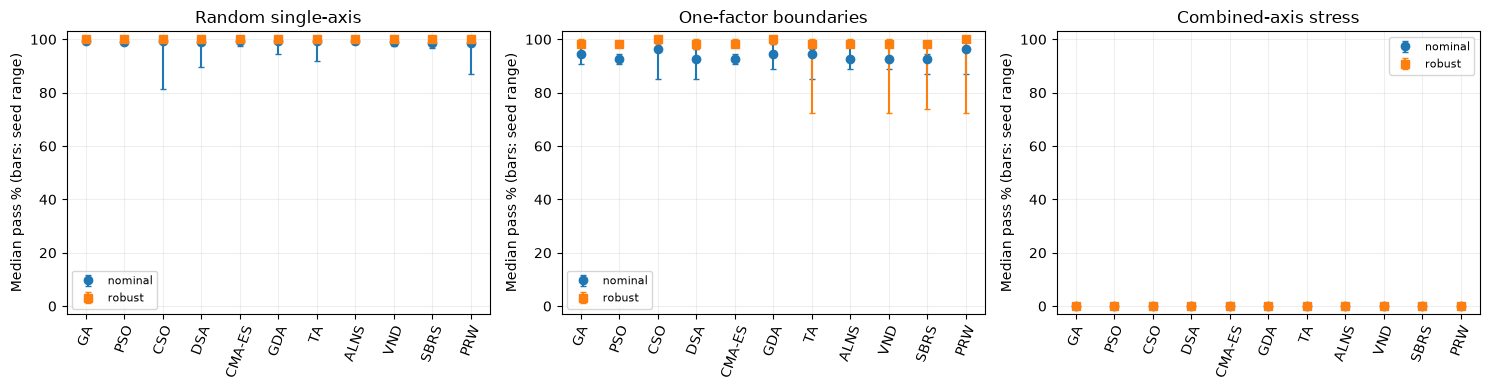

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,suite in zip(axes,['Random single-axis','One-factor boundaries','Combined-axis stress']):
    for mode,marker in [('nominal','o'),('robust','s')]:
        data=[next(r for r in all_validation if r['method']==m and r['training']==mode and r['suite']==suite) for m in METHODS]
        med=np.array([r['median_passes']/r['cases_per_controller']*100 for r in data])
        lo=np.array([r['minimum_passes']/r['cases_per_controller']*100 for r in data]); hi=np.array([r['maximum_passes']/r['cases_per_controller']*100 for r in data])
        ax.errorbar(np.arange(len(METHODS)),med,yerr=[med-lo,hi-med],fmt=marker,label=mode,capsize=2)
    ax.set_xticks(np.arange(len(METHODS)),list(METHODS),rotation=70)
    ax.set(title=suite,ylabel='Median pass % (bars: seed range)',ylim=(-3,103));ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();plt.show();plt.close(fig)


## Joint-boundary checks
Passing all sampled corners for a selected controller is not a guarantee over the full continuous uncertainty region.


In [5]:
show_table(load_csv(ROBUST/'results/corner_validation_summary.csv'),['mode','method','selection','seed','passes','cases','physical_passes','physical_cases'],limit=30)
show_table(load_csv(study('ALNS')/'results/selected_candidates.csv'),['mode','selection','seed','corner_passes','corner_cases'])


mode,method,selection,seed,passes,cases,physical_passes,physical_cases
nominal,GA,best,102,1152,1536,992,1344
nominal,GA,median,11,1088,1536,928,1344
nominal,PSO,best,107,1152,1536,992,1344
nominal,PSO,median,105,672,1536,544,1344
nominal,CSO,best,114,1152,1536,992,1344
nominal,CSO,median,127,1312,1536,1152,1344
nominal,DSA,best,117,1024,1536,864,1344
nominal,DSA,median,47,1280,1536,1120,1344
nominal,CMA-ES,best,47,832,1536,688,1344
nominal,CMA-ES,median,119,1024,1536,864,1344


mode,selection,seed,corner_passes,corner_cases
nominal,best,105,1152,1536
nominal,median,122,832,1536
robust,best,110,1344,1536
robust,median,104,1408,1536


## Inspect an individual compressed validation record
Change METHOD and the selected path to inspect another controller without loading the entire archive at once.


In [6]:
METHOD='ALNS'
record_path=sorted((study(METHOD)/'results/validation').glob('*.json.gz'))[0]
record=load_json(record_path)
print('Record:',record_path.relative_to(ROOT).as_posix())
print('Top-level type:',type(record).__name__)
print(json.dumps(record,indent=2)[:6000])


Record: pid using alns/results/validation/baseline_baseline_0.json.gz
Top-level type: dict
{
  "summary": {
    "mode": "baseline",
    "method": "baseline",
    "seed": 0,
    "robust_training_fitness": 1102.2417983869623,
    "training_passes": 21,
    "nominal_fitness": 1011.6167589636441,
    "nominal_passes": 5,
    "nominal_mean_settling_s": 0.5823333333333334,
    "nominal_worst_settling_s": 0.743,
    "single_axis_mc_passes": 285,
    "single_axis_mc_worst_settling_s": 1.2249999999999999,
    "single_axis_mc_worst_violation": 0.13336633344227755,
    "one_at_a_time_passes": 36,
    "one_at_a_time_worst_settling_s": 1.133,
    "one_at_a_time_worst_violation": 0.15464515722978167,
    "combined_stress_passes": 0,
    "combined_stress_worst_settling_s": 3.0,
    "combined_stress_worst_violation": 34.894544946847056
  },
  "cases": [
    {
      "name": "mc_000",
      "group": "single_axis_mc",
      "feasible": true,
      "violation": 0.0,
      "speed_score": 0.1374369053112393